# Análise dos Dados: BASE-DETECTION
***
* Repositório com o dataset original: [BASE-DETECTION](https://universe.roboflow.com/shandong-university-zvicd/base-detection-zyh6x).

### Importação dos Pacotes Utilitários
***

In [10]:
from collections import Counter
import matplotlib.pyplot as plt
import json
import utils

### Análise dos Dados
***

In [3]:
# carregando os rótulos no arquivo json dentro de um dicionário
json_path1 = '../datasets-descompactados/BASE-DETECTION-dataset/train/_annotations.coco.json'
json_path2 = '../datasets-descompactados/BASE-DETECTION-dataset/valid/_annotations.coco.json'
json_path3 = '../datasets-descompactados/BASE-DETECTION-dataset/test/_annotations.coco.json'

data1 = utils.load_json_file(json_path1)
data2 = utils.load_json_file(json_path2)
data3 = utils.load_json_file(json_path3)

In [4]:
# analisando as chaves de acesso do dicionário
data1.keys()

dict_keys(['info', 'licenses', 'categories', 'images', 'annotations'])

In [4]:
# analisando as informações do conjunto de imagens
data1['info']

{'year': '2023',
 'version': '1',
 'description': 'Exported from roboflow.com',
 'contributor': '',
 'url': 'https://public.roboflow.com/object-detection/undefined',
 'date_created': '2023-08-17T22:11:34+00:00'}

In [5]:
# analisando as categorias de rotulação dos dados com seus respectivos IDs
data1['categories']

[{'id': 0, 'name': 'towers', 'supercategory': 'none'},
 {'id': 1, 'name': 'Flammable firewood', 'supercategory': 'towers'},
 {'id': 2, 'name': 'soil erosion', 'supercategory': 'towers'},
 {'id': 3, 'name': 'trees', 'supercategory': 'towers'}]

In [6]:
# inicializando um dicionário vazio com os IDs das imagens
images_ids1 = utils.initialize_images_ids_with_dict(data1)
images_ids2 = utils.initialize_images_ids_with_dict(data2)
images_ids3 = utils.initialize_images_ids_with_dict(data3)

# obtendo a quantidade de instâncias de objeto por imagem
for info in data1['annotations']:
    images_ids1[info['image_id']].append(info['category_id'])

for info in data2['annotations']:
    images_ids2[info['image_id']].append(info['category_id'])

for info in data3['annotations']:
    images_ids3[info['image_id']].append(info['category_id'])

In [8]:
# contando a quantidade de instâncias de objetos em todo o conjunto de imagens
count_instances = {'Flammable firewood': 0, 'soil erosion': 0, 'trees': 0}

for images_instances in images_ids1.values():
    count_aux = Counter(images_instances)
    count_instances['Flammable firewood'] += count_aux[1]
    count_instances['soil erosion'] += count_aux[2]
    count_instances['trees'] += count_aux[3]

for images_instances in images_ids2.values():
    count_aux = Counter(images_instances)
    count_instances['Flammable firewood'] += count_aux[1]
    count_instances['soil erosion'] += count_aux[2]
    count_instances['trees'] += count_aux[3]

for images_instances in images_ids3.values():
    count_aux = Counter(images_instances)
    count_instances['Flammable firewood'] += count_aux[1]
    count_instances['soil erosion'] += count_aux[2]
    count_instances['trees'] += count_aux[3]

print(count_instances)

{'Flammable firewood': 26, 'soil erosion': 86, 'trees': 16}


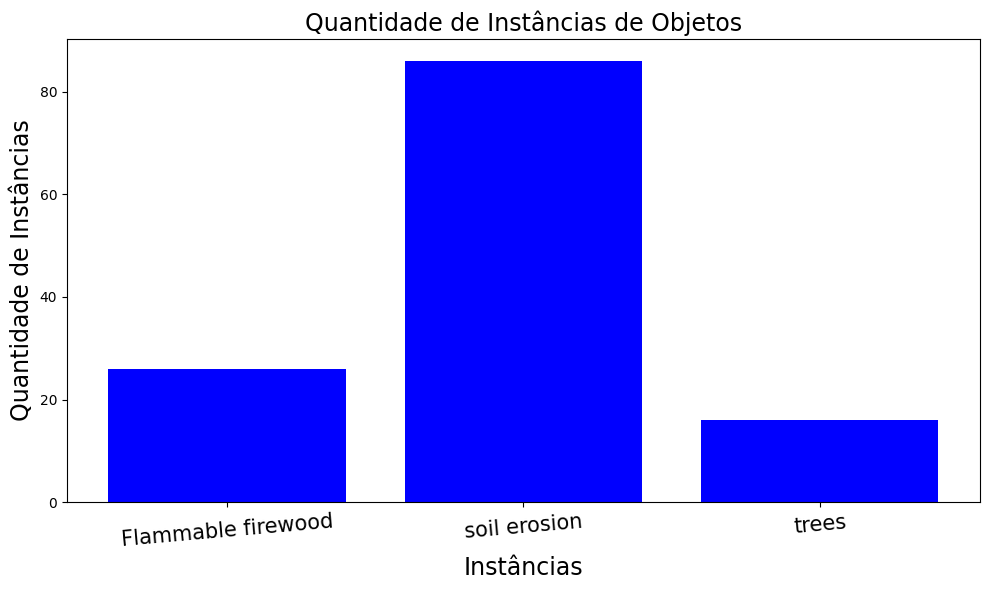

In [11]:
# extraindo as chaves e os valores do dicionário
classes = list(count_instances.keys())
quantities = list(count_instances.values())

# configurações para a plotagem do gráfico de barras
plt.figure(figsize = (10, 6))  

plt.bar(classes, quantities, color = 'blue')  

plt.xlabel('Instâncias', size = 17)
plt.ylabel('Quantidade de Instâncias', size = 17)
plt.title('Quantidade de Instâncias de Objetos', size = 17)
plt.xticks(rotation = 5, size = 15)  

plt.tight_layout()
plt.show()

In [13]:
# contando a quantidade de instâncias de objetos em todo o conjunto de imagens
verify_towers = {'Imagens com Torres': 0, 'Imagens sem Torres': 0}

for images_instances in images_ids1.values():
    count_aux = Counter(images_instances)
    if (count_aux[1] != 0) or (count_aux[2] != 0) or (count_aux[3] != 0):
        verify_towers['Imagens com Torres'] += 1
    else:
        verify_towers['Imagens sem Torres'] += 1

for images_instances in images_ids2.values():
    count_aux = Counter(images_instances)
    if (count_aux[1] != 0) or (count_aux[2] != 0) or (count_aux[3] != 0):
        verify_towers['Imagens com Torres'] += 1
    else:
        verify_towers['Imagens sem Torres'] += 1

for images_instances in images_ids3.values():
    count_aux = Counter(images_instances)
    if (count_aux[1] != 0) or (count_aux[2] != 0) or (count_aux[3] != 0):
        verify_towers['Imagens com Torres'] += 1
    else:
        verify_towers['Imagens sem Torres'] += 1

print(verify_towers)

{'Imagens com Torres': 58, 'Imagens sem Torres': 0}
